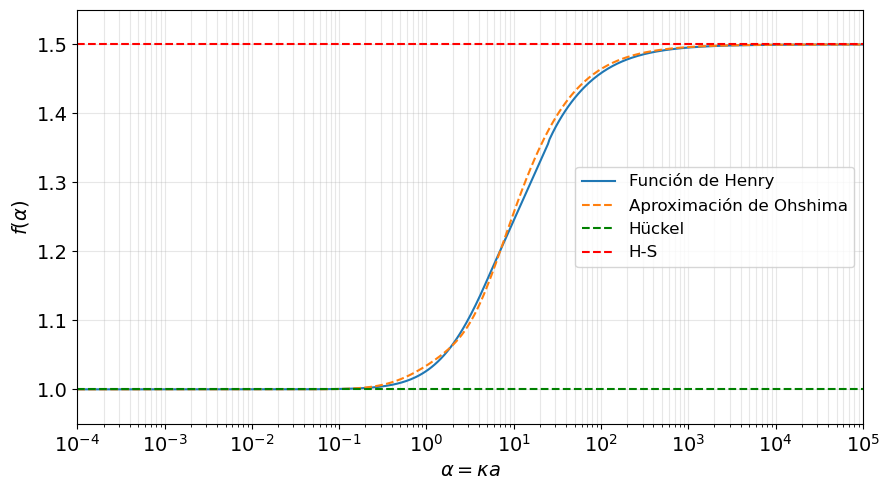

α =    0.1  Henry = 1.000545  Ohshima = 1.000516
α =      1  Henry = 1.026665  Ohshima = 1.034407
α =      4  Henry = 1.132313  Ohshima = 1.121406
α =     10  Henry = 1.244698  Ohshima = 1.256014
α =     15  Henry = 1.294429  Ohshima = 1.314869
α =     30  Henry = 1.379444  Ohshima = 1.393264
α =    100  Henry = 1.458420  Ohshima = 1.464300
α =   1000  Henry = 1.495537  Ohshima = 1.496269


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import exp1

def henry(alpha):

    if 0 < alpha < 5:

        I = exp1(alpha)

        f = (1 + alpha**2/16 - 5*alpha**3/48
             - alpha**4/96 + alpha**5/96
             + (alpha**4/8 - alpha**6/96)
             * np.exp(alpha) * I)

    elif alpha > 25:

        f = (3/2 - 9/(2*alpha)
             + 75/(2*alpha**2) - 330/alpha**3)

    else:

        f_4 = henry(4)
        f_30 = henry(30)

        f = f_4 + (f_30 - f_4) * (
            (np.log10(alpha) - np.log10(4))
            / (np.log10(30) - np.log10(4))
        )

    return f


def ohshima(alpha):

    delta = 2.5 / (1 + 2*np.exp(-alpha))

    f = 1 + 1 / (2*(1 + delta/alpha)**3)

    return f


# Valores de alpha
alphas = np.logspace(-4, 5, 500)

# Calcular ambas funciones
funcion_henry = [henry(alpha) for alpha in alphas]
funcion_ohshima = [ohshima(alpha) for alpha in alphas]

# Representación gráfica
plt.figure(figsize=(9, 5))
plt.semilogx(alphas, funcion_henry,label="Función de Henry")
plt.semilogx(alphas, funcion_ohshima,linestyle="--",label="Aproximación de Ohshima")

# Límites asintóticos
plt.axhline(1, linestyle="--", color="green",label="Hückel")
plt.axhline(1.5, linestyle="--",color="red",label="H-S")

plt.xlabel(r"$\alpha = \kappa a$", fontsize=14)
plt.ylabel(r"$f(\alpha)$", fontsize=14)

plt.tick_params(axis="both", labelsize=14)

plt.xlim(1e-4, 1e5)
plt.ylim(0.95, 1.55)

plt.grid(True, which="both", alpha=0.3)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()


# Resultados numéricos
valores = [0.1, 1, 4, 10, 15, 30, 100, 1000]

for alpha in valores:
    print(f"α = {alpha:6g}  "f"Henry = {henry(alpha):.6f}  "f"Ohshima = {ohshima(alpha):.6f}")
